In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [2]:
### simplify all the conventions (transposes, stacks, input_shape, etc)

In [3]:
### two main conventions in question

### 1) what should the rotation convention be ?
### 2) where should we try to match the projection convention to ?

### other - plotting notation and conventions could also be causing confusion

In [4]:
def cartesian_to_voxel(p, N):
    """
    points (p): (n_p, 3) array of (x,y,z) in [-1,1]
    N: voxel size (assume equal dimensions and spacing) nx = ny = nz = N
        axis 0 = x  (out of screen)
        axis 1 = z  (up) but flipped so z=+1 maps to index 0
        axis 2 = y  (right)
    Returns: (n_p, 3) integer indices (ix, iz, iy)
    Notes: int is equivalent to 'floor' nearest neighbor interpolation (I think?)
    """

    x, y, z = p[..., 0], p[..., 1], p[..., 2]

    # x flip: x = +1 -> ix = 0, x = -1 -> ix = nx-1
    ix = ((1 - x) * 0.5 * (N - 1)).astype(int)

    # z flip: z = +1 -> iz = 0, z = -1 -> iz = nz-1
    iz = ((1 - z) * 0.5 * (N - 1)).astype(int)

    # y normal: y = -1 -> 0, y = +1 -> ny-1
    iy = ((y + 1) * 0.5 * (N - 1)).astype(int)

    return np.stack([ix, iy, iz])



def place_points_into_volume(idx, N, value=1):
    """
    Write voxels into a NumPy volume with geometry-preserving layout:
        volume[z, y, x]
    idx: (3, n_points) voxel indices
    """
    volume = np.zeros((N, N, N), dtype=np.float32)

    ix, iy, iz = idx  # unpack integer indices

    # Geometry-preserving placement: z->axis0, y->axis1, x->axis2
    volume[ix, iz, iy] = value
    
    return volume


def generate_voxel_array_from_points(p, N, value=1):

    idx = cartesian_to_voxel(p, N)
    vol = place_points_into_volume(idx, N, value)

    return vol

In [5]:
N = 67
sigma = 2
z = utils.generate_centered_gaussian(d=3, sigma=sigma, N=N)

omega = np.deg2rad(180)
theta = np.deg2rad(0)
phi = np.deg2rad(0)

In [6]:
### 1) generate points -> voxel array

p1 = np.array([0, 0, 0.65])
p = np.array([p1])

f1 = generate_voxel_array_from_points(p1, N)

f1 = utils.signal_convolution(f1, z)


### roate the points then generate voxel array

R = transforms.rotate_zyz(omega, theta, phi)  # order is (Rphi @ Rtheta @ Romega)

p_r = (R @ p.T).T # rotated points 

f1_r = generate_voxel_array_from_points(p_r, N)

f1_r = utils.signal_convolution(f1_r, z)

In [7]:
print(np.round(p, 3))
print(np.round(p_r , 3))

[[0.   0.   0.65]]
[[0.   0.   0.65]]


In [8]:
### 3) generate voxel array

### translate_3d is numpy conventions, intial Gaussian is centered [N//2 , N//2 , N//2]
### using the conventions I thought made since, this would correspond to
### translate_3d ( +axis 0 = -x (into the screen), +axis 1 = -z (bottom of array), +axis 2 =  +y (right of array) )
z_1 = transforms.translate_3d(z, 0, -24, 0)
f2 = z_1

### rotate the voxel array directly

f2_r = transforms.rotate_voxel_zyz(f2, omega, theta, phi)

CARTESIAN POINT


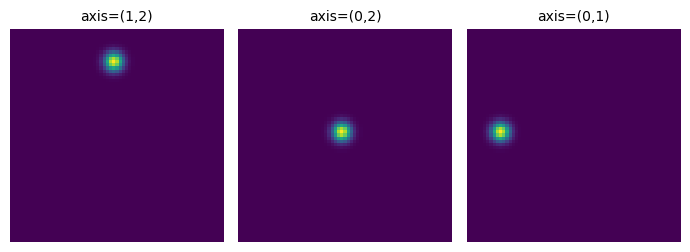

NUMPY POINT


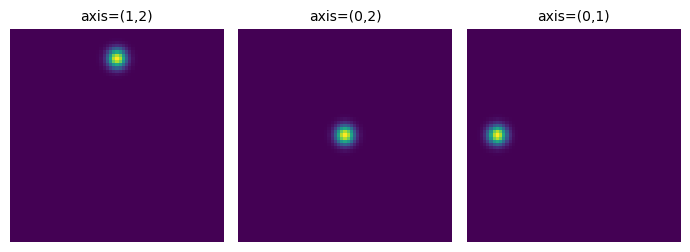

In [9]:
print('CARTESIAN POINT')
plots.orthogonal_2D_projection_plot(f1)

print('NUMPY POINT')
plots.orthogonal_2D_projection_plot(f2)

CARTESIAN POINT ROTATED


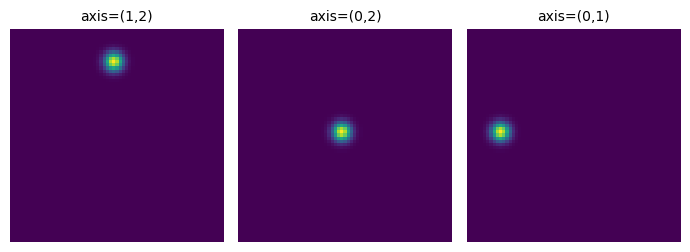

NUMPY POINT ROTATED


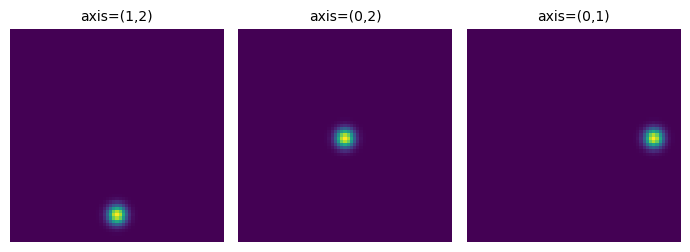

In [10]:
print('CARTESIAN POINT ROTATED')
plots.orthogonal_2D_projection_plot(f1_r)

print('NUMPY POINT ROTATED')
plots.orthogonal_2D_projection_plot(f2_r)

In [11]:
Pf_rt = transforms.Transform(f1, d=3).radon_transform()[0]

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/finufft/_interfaces.py:336: UserWarning: Argument `data` does not satisfy the following requirement: C. Copying array (this may reduce performance)
  warnings.warn(f"Argument `{name}` does not satisfy the following requirement: {prop}. Copying array (this may reduce performance)")


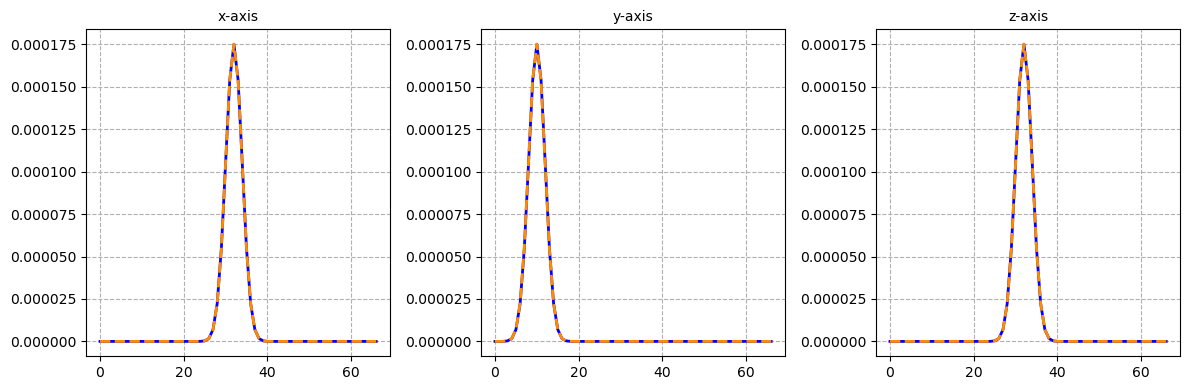

In [12]:
plots.orthogonal_1D_projection_comparison_plot(f1 * (2-2/N)**2/N**2, Pf_rt)